# Module project: build an image codec with K-means

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-4-vq-image-codec.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-4-latent-variables/files/project-4-vq-image-codec.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/vq-image-codec` folder in the course files, to check your work.
- **Data**: No download: the photo ships with scikit-learn (`load_sample_image('china.jpg')`); any photo of your own works too.

In [ ]:
%pip install -q torch numpy pillow scikit-learn matplotlib

Section 15.1.1 points out that K-means is also a compression method: replace every pixel by the nearest of K "codebook"
colours, and you only need to store the K colours plus `log2 K` bits per pixel, instead of 24. In the Build lesson you
recoloured a photo that way. In this project you turn the idea into a **real codec**: a program that writes actual
compressed files, reads them back, decodes them, and is measured honestly against PNG and JPEG.

The notebook attached above builds and runs the whole project; the reference code is in the course files under
`projects/vq-image-codec`.

## What you'll build

```mermaid
flowchart LR
    A[photo<br/>24 bits per pixel] --> B[kmeans.py<br/>K colours,<br/>K-means++]
    B --> C[codec.py<br/>palette + packed indices<br/>+ optional zlib]
    C --> D[.vq file]
    D --> E[decompress<br/>back to an image]
    E --> F[benchmark.py<br/>size and quality<br/>vs PNG and JPEG]
```

## Set up the project

```bash
mkdir vq-image-codec && cd vq-image-codec
python -m venv .venv && source .venv/bin/activate
pip install torch numpy pillow scikit-learn matplotlib
git init
```

scikit-learn is only used for the sample photo it ships with; any photo of your own works too.

```text
vq-image-codec/
    .gitignore
    README.md
    benchmark.py
    codec.py
    init_compare.py
    kmeans.py
    requirements.txt
```

In [ ]:
%%writefile requirements.txt
torch
numpy
pillow
scikit-learn
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
outputs/
__pycache__/
.venv/

Writing .gitignore


## Step 1: K-means, with a better start

The algorithm alternates two steps until nothing changes (section 15.1): give each point to its nearest centre, then move
each centre to the mean of its points. Each step can only lower the distortion `J` (equation 15.1), the total squared
distance from points to their centres, so it always converges, but only to a **local** minimum that depends on the start.

**K-means++** chooses better starting points: the first centre is a random point, and each next one is chosen with
probability proportional to its squared distance from the nearest centre so far. Far-away colours get a centre early.

In [ ]:
%%writefile kmeans.py
"""K-means clustering in PyTorch (Bishop, section 15.1), with K-means++ initialization."""
import torch


def init_plus_plus(X, K, g):
    """K-means++: each new centre is a random data point, chosen with probability proportional to its squared
    distance from the nearest centre so far. Spreads the starting centres out."""
    centres = X[torch.randint(len(X), (1,), generator=g)]
    for _ in range(K - 1):
        d2 = torch.cdist(X, centres).min(1).values ** 2
        centres = torch.cat([centres, X[torch.multinomial(d2, 1, generator=g)]])
    return centres


def kmeans(X, K, iters=30, seed=0, init="++"):
    """Returns centres (K, D), the cluster of each point (N,), and the distortion J after each iteration."""
    g = torch.Generator().manual_seed(seed)
    centres = init_plus_plus(X, K, g) if init == "++" else X[torch.randperm(len(X), generator=g)[:K]].clone()
    history = []
    for _ in range(iters):
        labels = torch.cdist(X, centres).argmin(1)                               # E step: nearest centre
        history.append(((X - centres[labels]) ** 2).sum().item())                 # distortion J (equation 15.1)
        for k in range(K):                                                         # M step: mean of each cluster
            members = X[labels == k]
            if len(members):
                centres[k] = members.mean(0)
    return centres, labels, history

Writing kmeans.py


## Step 2: the codec

The file format is simple, and that's the point: you know where every byte goes.

- A **header**: height, width, K, bits per index, and whether zlib was used (8 bytes).
- The **palette**: K colours × 3 bytes.
- The **indices**: one per pixel, each written with exactly `ceil(log2 K)` bits. `np.packbits` packs 8 bits into each byte.

That's the book's count, `24K + N log2 K` bits, as a real file. Optionally, the index bytes go through `zlib`, the same
kind of general-purpose compressor as gzip from your part 1 text compressor. **PSNR** (peak signal-to-noise ratio) measures
quality: about 30 dB and above looks good to most people.

In [ ]:
%%writefile codec.py
"""A real image codec based on vector quantization (section 15.1.1): store a palette of K colours, and for each
pixel only the index of its colour, packed into log2(K) bits."""
import math
import struct
import zlib
import numpy as np
import torch
from kmeans import kmeans


def compress(img, K, seed=0, sample=20000, entropy=False):
    """img: (H, W, 3) uint8 array -> bytes. K-means runs on a random sample of pixels, for speed.
    entropy=True also squeezes the index stream with zlib: neighbouring pixels often share a colour."""
    H, W, _ = img.shape
    pixels = torch.tensor(img.reshape(-1, 3), dtype=torch.float32)
    g = torch.Generator().manual_seed(seed)
    centres, _, _ = kmeans(pixels[torch.randperm(len(pixels), generator=g)[:sample]], K, seed=seed)
    palette = centres.round().clamp(0, 255).to(torch.uint8)
    labels = torch.cdist(pixels, palette.float()).argmin(1).numpy()
    bits = max(1, math.ceil(math.log2(K)))
    bit_array = ((labels[:, None] >> np.arange(bits)[::-1]) & 1).astype(np.uint8)  # each index as `bits` bits
    body = np.packbits(bit_array.flatten()).tobytes()
    if entropy:
        body = zlib.compress(body, 9)
    header = struct.pack("<HHHBB", H, W, K, bits, int(entropy))
    return header + palette.numpy().tobytes() + body


def decompress(data):
    H, W, K, bits, entropy = struct.unpack("<HHHBB", data[:8])
    palette = np.frombuffer(data[8:8 + 3 * K], dtype=np.uint8).reshape(K, 3)
    body = data[8 + 3 * K:]
    if entropy:
        body = zlib.decompress(body)
    bit_array = np.unpackbits(np.frombuffer(body, dtype=np.uint8))[:H * W * bits].reshape(-1, bits)
    labels = (bit_array * (1 << np.arange(bits)[::-1])).sum(1)
    return palette[labels].reshape(H, W, 3)


def psnr(a, b):
    """Peak signal-to-noise ratio in decibels: higher is closer to the original (30+ dB looks good)."""
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return 10 * math.log10(255 ** 2 / mse)

Writing codec.py


## Step 3: benchmark it

In [ ]:
%%writefile benchmark.py
"""Compress a photo with K = 2 to 256 colours, check the round trip, and compare file sizes with PNG and JPEG."""
import io
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image
from codec import compress, decompress, psnr

img = load_sample_image("china.jpg")                 # a 640 x 427 photo that ships with scikit-learn
H, W, _ = img.shape
raw = H * W * 3
Path("outputs").mkdir(exist_ok=True)


def saved_size(fmt, **kw):
    buf = io.BytesIO(); Image.fromarray(img).save(buf, fmt, **kw); return len(buf.getvalue())


print(f"photo: {W} x {H} pixels, raw size {raw:,} bytes (24 bits per pixel)\n")
print(f"{'format':14s} {'bytes':>9s} {'bits/pixel':>10s} {'PSNR (dB)':>9s}")
print(f"{'PNG (lossless)':14s} {saved_size('PNG'):9,d} {8 * saved_size('PNG') / (H * W):10.2f} {'perfect':>9s}")
jpg = saved_size("JPEG", quality=75)
buf = io.BytesIO(); Image.fromarray(img).save(buf, "JPEG", quality=75)
print(f"{'JPEG q75':14s} {jpg:9,d} {8 * jpg / (H * W):10.2f} {psnr(img, np.array(Image.open(buf))):9.1f}")
shown = {}
for K in [2, 4, 8, 16, 32, 64, 256]:
    data = compress(img, K)
    back = decompress(data)
    Path(f"outputs/china_K{K}.vq").write_bytes(data)
    print(f"{'VQ, K = ' + str(K):14s} {len(data):9,d} {8 * len(data) / (H * W):10.2f} {psnr(img, back):9.1f}")
    if K in (4, 16, 64):
        shown[K] = back
for K in [16, 32, 64]:
    data = compress(img, K, entropy=True)
    back = decompress(data)
    print(f"{'VQ+zlib, K=' + str(K):14s} {len(data):9,d} {8 * len(data) / (H * W):10.2f} {psnr(img, back):9.1f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 2.9))
axes[0].imshow(img); axes[0].set_title("original (24 bits/pixel)")
for ax, (K, im) in zip(axes[1:], shown.items()):
    ax.imshow(im); ax.set_title(f"K = {K} colours ({np.log2(K):.0f} bits/pixel)")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig("outputs/compare.png", dpi=100)
print("\nsaved outputs/compare.png")

Writing benchmark.py


In [ ]:
!python benchmark.py

photo: 640 x 427 pixels, raw size 819,840 bytes (24 bits per pixel)

format             bytes bits/pixel PSNR (dB)
PNG (lossless)   489,058      14.32   perfect
JPEG q75          61,147       1.79      30.0
VQ, K = 2         34,174       1.00      17.0
VQ, K = 4         68,340       2.00      21.5
VQ, K = 8        102,512       3.00      24.7
VQ, K = 16       136,696       4.00      27.5
VQ, K = 32       170,904       5.00      29.7
VQ, K = 64       205,160       6.01      32.3
VQ, K = 256      274,056       8.02      36.3
VQ+zlib, K=16     55,552       1.63      27.5
VQ+zlib, K=32     86,999       2.55      29.7
VQ+zlib, K=64    110,356       3.23      32.3

saved outputs/compare.png


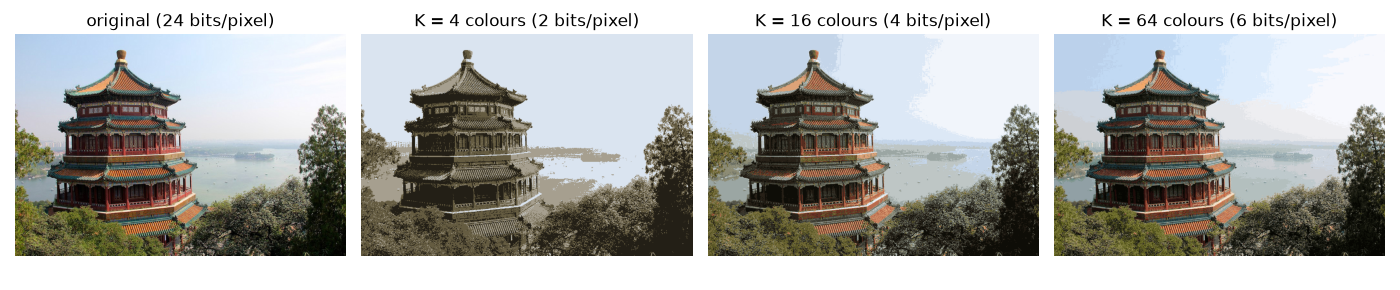

In [ ]:
from IPython.display import Image
Image('outputs/compare.png')

Read the table carefully, because it holds three lessons.

1. **The book's formula is right.** K = 16 costs exactly 4.00 bits per pixel, K = 256 costs 8.02 (the palette adds a
   little). Quality rises with K: 17 dB with two colours, 36 dB with 256.
2. **Plain vector quantization is a weak codec.** JPEG reaches 30 dB at 1.79 bits per pixel; K-means needs K = 32,
   5 bits per pixel, for the same quality.
3. **Entropy coding closes much of the gap.** Neighbouring pixels usually get the same colour, so the index stream is very
   repetitive, and zlib more than halves it: K = 32 drops from 5.00 to 2.55 bits per pixel at the same quality. That's the
   lesson of your part 1 text compressor again: predictable data compresses.

JPEG still wins, because it does something K-means can't: it transforms 8 × 8 blocks into frequencies and throws away the
detail human eyes don't notice. Saying **why** your method loses to the standard is part of a good README.

## Step 4: does the start matter?

In [ ]:
%%writefile init_compare.py
"""K-means only finds a local minimum of the distortion J. Does the starting point matter? 5 seeds, two inits."""
import torch
from sklearn.datasets import load_sample_image
from kmeans import kmeans

pixels = torch.tensor(load_sample_image("china.jpg").reshape(-1, 3), dtype=torch.float32)
sample = pixels[torch.randperm(len(pixels), generator=torch.Generator().manual_seed(0))[:20000]]
for init in ["random", "++"]:
    finals, firsts = [], []
    for seed in range(5):
        _, _, history = kmeans(sample, 16, seed=seed, init=init)
        firsts.append(history[0]); finals.append(history[-1])
    name = "K-means++" if init == "++" else "random points"
    print(f"{name:14s} J at start {sum(firsts) / 5 / 1e6:7.1f} M, after 30 steps: "
          + ", ".join(f"{f / 1e6:.1f}" for f in finals) + " M")

Writing init_compare.py


In [ ]:
!python init_compare.py

random points  J at start    15.5 M, after 30 steps: 7.3, 8.1, 7.4, 7.2, 8.0 M
K-means++      J at start    12.3 M, after 30 steps: 7.1, 7.3, 7.1, 7.4, 7.2 M


K-means++ starts with a lower distortion (12.3 million against 15.5 million) and, more importantly, ends more
**consistently**: 7.1 to 7.4 million over five seeds, against 7.2 to 8.1 for random starting points. A bad random start
can leave K-means stuck in a poor local minimum; spreading the centres out avoids most of them. That's why K-means++ is
the default in every major library.

## Step 5: write the README and publish

In [ ]:
%%writefile README.md
# Vector-quantization image codec

A working lossy image codec built on K-means (K-means++ initialization, written in PyTorch): it stores a palette of K
colours and, for each pixel, the index of its nearest colour packed into log2 K bits, optionally squeezed with zlib.
Files are written, read back and decoded, and compared with PNG and JPEG on the same photo.

![compare](outputs/compare.png)

## Results (640 x 427 photo, raw 819,840 bytes)

| format | bytes | bits/pixel | PSNR (dB) |
|---|---|---|---|
| PNG (lossless) | 489,058 | 14.32 | perfect |
| JPEG, quality 75 | 61,147 | 1.79 | 30.0 |
| VQ, K = 16 | 136,695 | 4.00 | 27.5 |
| VQ, K = 32 | 170,903 | 5.00 | 29.7 |
| VQ + zlib, K = 16 | 55,552 | 1.63 | 27.5 |
| VQ + zlib, K = 32 | 86,999 | 2.55 | 29.7 |

K-means++ initialization gave final distortions of 7.1 to 7.4 million over 5 seeds, against 7.2 to 8.1 million for
random starting points.

## Run it

```bash
pip install -r requirements.txt
python benchmark.py      # compress, decompress, compare with PNG and JPEG
python init_compare.py   # random vs K-means++ initialization
```

## What I learned

- K-means is vector quantization: each pixel is replaced by its nearest codebook colour, costing log2 K bits.
- Packing indices into a real file, and decoding it back, keeps the measurements honest.
- Entropy coding the indices more than halves the size; JPEG still wins by using transforms tuned to human vision.

Based on section 15.1 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Vector quantization image codec with K-means++"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/vq-image-codec.git
git push -u origin main
```

## Make it yours

- **A command-line tool.** Add `vq.py compress photo.jpg -k 32 -o photo.vq` and `vq.py decompress photo.vq -o out.png`
  with `argparse`, and try it on your own photos.
- **Better entropy coding.** Instead of zlib, store each pixel's index as "same as the pixel to the left" or the
  index itself. Does a simple prediction beat zlib?
- **Blocks instead of pixels.** Quantize 2 × 2 blocks of pixels (12 numbers each) instead of single pixels. At the same
  bits per pixel, is the quality better?
- **A size target.** Search for the smallest K (with zlib) that reaches a given PSNR, say 30 dB, for any input photo.

## On your CV

> **Image codec with K-means** (Python, PyTorch): vector-quantization codec with K-means++ (palette plus bit-packed
> indices, optional zlib), with a verified encode/decode round trip; 2.55 bits/pixel at 29.7 dB PSNR, benchmarked against
> PNG (14.3) and JPEG (1.8). github.com/YOUR-USERNAME/vq-image-codec

## Check yourself

- [ ] VQ and VQ + zlib give exactly the same PSNR for each K: the zlib step loses nothing.
- [ ] You can derive the file size from K and the image size, before running the code.
- [ ] You can explain why JPEG still wins.